# ¿Quién abandona el banco y a quién retener primero?

Semanas 7, 8 y 9 | Dataset 10,000 clientes de un banco en Francia, Alemania y España

El problema. Un banco con 10,000 clientes en Francia, Alemania y España perdió al 20% de ellos. El equipo de retención no puede llamar a todos, así que necesita saber a quién contactar primero.

**Qué hace este notebook


| Parte | Pregunta | Lo que usamos (visto en clase) |
|---|---|---|
| 1 · Datos | ¿Qué tenemos? | `read_csv`, `info`, `describe`, one-hot, `train_test_split`, `StandardScaler` |
| 2 · Semana 7: Regresión | ¿Sirve una recta para predecir el abandono? | Mapa de calor, `LinearRegression`, R², RMSE, MAE, residuales |
| 3 · Semana 8: Clasificación | ¿Quién se va a ir? | Regresión logística, K-NN, árbol de decisión, matriz de confusión, ROC, umbral |
| 4 · Semana 9: Clustering | ¿Qué grupos de clientes hay? | K-Means, método del codo, Silhouette, Expectation-Maximization |
| 5 · Conclusiones | ¿A quién retener primero? | Lo que aprendimos de las tres semanas |


## 1. Datos | Librerias

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             confusion_matrix, accuracy_score, recall_score, precision_score,
                             f1_score, roc_curve, roc_auc_score, silhouette_score)

SEMILLA = 42

In [10]:
try:
    from google.colab import files
    import os
    if not os.path.exists("Churn_Modelling.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("Churn_Modelling.csv")
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(df.shape)
print(f"Tasa de abandono: {df['Exited'].mean():.1%}")
df.head()

(10000, 11)
Tasa de abandono: 20.4%


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Revisar datos

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [12]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [13]:
# ¿Cuántos clientes se fueron? (Exited = 1 significa que abandonó)
print(df["Exited"].value_counts())
print(f"Tasa de abandono: {df['Exited'].mean():.1%}")

Exited
0    7963
1    2037
Name: count, dtype: int64
Tasa de abandono: 20.4%


10,000 Clientes, ningún dato vacio y 20.4% abandonó. Es decir, de cada 10 clientes, 2 se van.  

##Preparar datos para los modelos

1. One-hot: los modelos solo entienden números, así que Geography y Gender se convierten en columnas de 0 y 1.
   Con drop_first=True se quita una columna de cada una (Francia y Mujer) porque se deduce de las demás: si no es Alemania ni España, es Francia.
2. Separar X (las pistas) de Y (lo que queremos predecir: Exited).
3. Dividir en entrenamiento (80%) y prueba (20%). El modelo aprende con el primero y lo calificamos con el segundo, que nunca vio. stratify=y hace que los dos grupos tengan el mismo 20% de abandono.
4. Estandarizar: poner todas las variables en la misma escala (el saldo está en miles y la edad en decenas).

1.   Elemento de lista
2.   Elemento de lista



In [14]:
datos = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True, dtype=int)
X = datos.drop(columns="Exited")
y = datos["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

scaler = StandardScaler().fit(X_train)  # se ajusta SOLO con entrenamiento
X_train_esc = scaler.transform(X_train)
X_test_esc = scaler.transform(X_test)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (8000, 11) | Prueba: (2000, 11)


## 2 · Semana 7: Regresión
**Pregunta: ¿sirve una recta para predecir si un cliente se va?

### 2.1 Mapa de calor de correlaciones
La correlación va de **−1 a 1**. Cerca de 1: cuando una sube, la otra también. Cerca de −1: cuando una sube, la otra baja. Cerca de 0: no hay relación en línea recta.
Nos interesa sobre todo la fila de Exited.

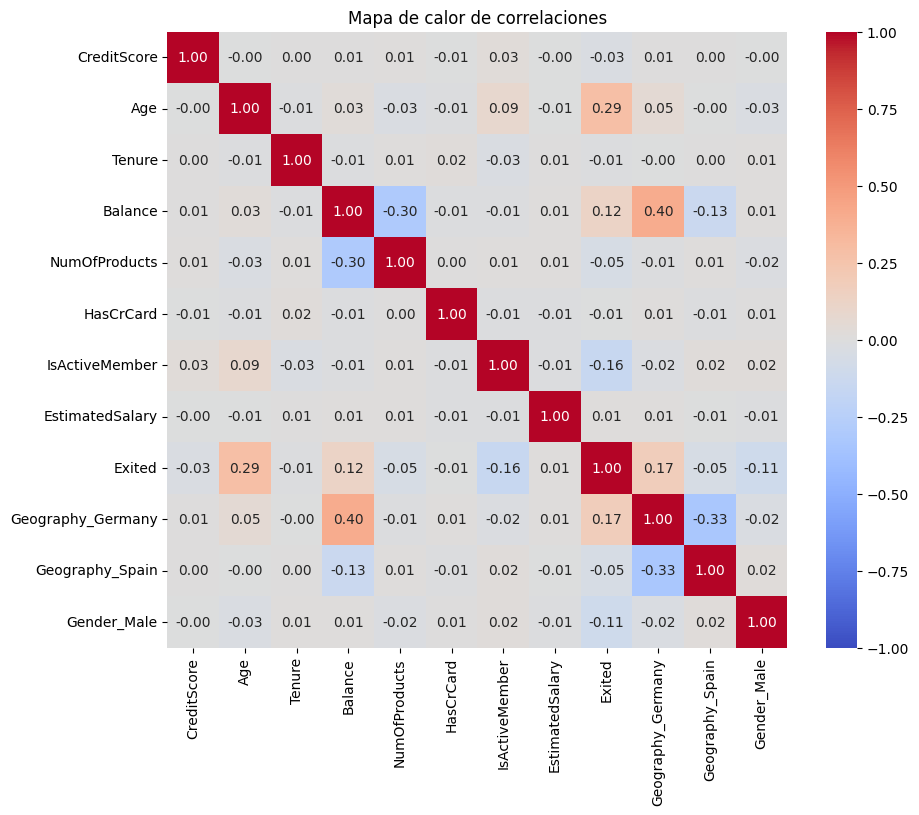

Correlación de cada variable con el abandono (Exited):
Age                  0.285
Geography_Germany    0.173
IsActiveMember      -0.156
Balance              0.119
Gender_Male         -0.107
Geography_Spain     -0.053
NumOfProducts       -0.048
CreditScore         -0.027
Tenure              -0.014
EstimatedSalary      0.012
HasCrCard           -0.007
Name: Exited, dtype: float64


In [15]:
corr = datos.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Mapa de calor de correlaciones")
plt.show()

print("Correlación de cada variable con el abandono (Exited):")
print(corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False).round(3))

**Qué vemos:**
- Lo que más se relaciona con irse es la **edad** (0.29) y ser de **Alemania** (0.17).
- Ser **miembro activo** va en sentido contrario (−0.16): los activos se van menos.
- Todas las correlaciones son **débiles** (ninguna pasa de 0.3). Ninguna variable sola explica el abandono.

### 2.2 Regresión lineal
Tratamos `Exited` (0 o 1) como si fuera un número y le ajustamos una recta. Luego la calificamos con las métricas de la semana 7:
- **R²:** qué parte del comportamiento explica el modelo (1 = todo, 0 = nada).
- **RMSE y MAE:** cuánto se equivoca en promedio.

In [16]:
lineal = LinearRegression()
lineal.fit(X_train_esc, y_train)
y_pred = lineal.predict(X_test_esc)

print(f"R²   = {r2_score(y_test, y_pred):.3f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"MAE  = {mean_absolute_error(y_test, y_pred):.3f}")
print(f"Predicciones menores a 0: {(y_pred < 0).sum()} | mayores a 1: {(y_pred > 1).sum()}")
print(f"Rango de las predicciones: {y_pred.min():.2f} a {y_pred.max():.2f}")

R²   = 0.154
RMSE = 0.370
MAE  = 0.284
Predicciones menores a 0: 174 | mayores a 1: 0
Rango de las predicciones: -0.21 a 0.72


**Qué vemos:** la recta solo explica el **15%** del abandono (R² = 0.15) y da **predicciones negativas**, como "−0.21". Una probabilidad negativa no tiene sentido.

### 2.3 Coeficientes: ¿hacia dónde empuja cada variable?
Como los datos están estandarizados, podemos comparar los coeficientes entre sí. Positivo = empuja hacia irse. Negativo = empuja hacia quedarse.

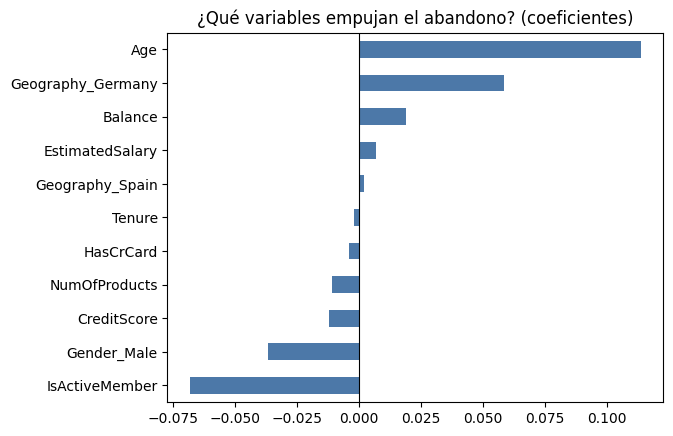

In [19]:
coef = pd.Series(lineal.coef_, index=X.columns).sort_values()
coef.plot(kind="barh", color="#4C78A8")
plt.axvline(0, color="k", lw=0.8)
plt.title("¿Qué variables empujan el abandono? (coeficientes)")
plt.show()

### 2.4 Residuales
El residual es el error de cada predicción: **valor real − predicción**. Si el modelo es bueno, los errores forman una sola campana centrada en 0 y una nube sin forma.

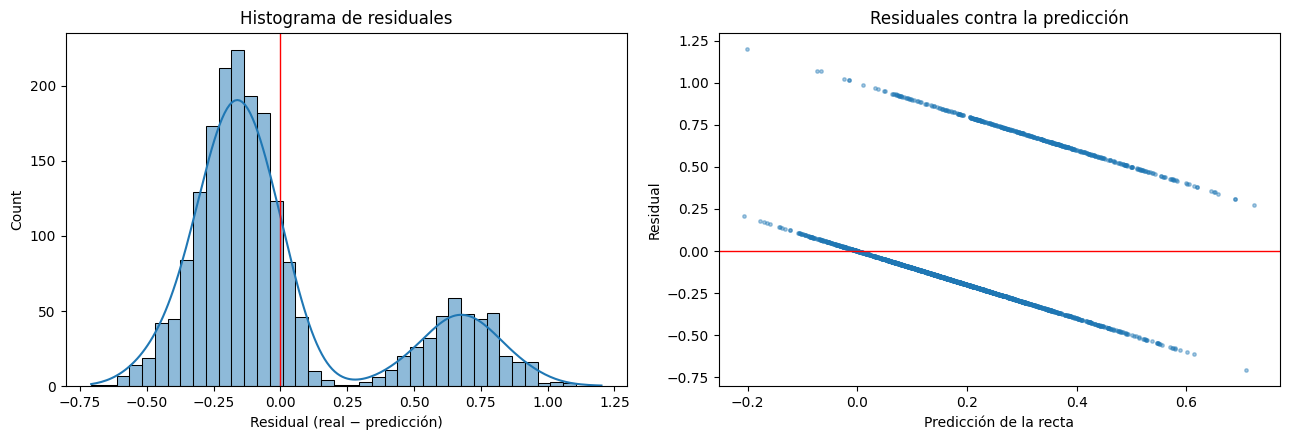

In [20]:
residuales = y_test - y_pred
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(residuales, bins=40, kde=True, ax=a1)
a1.axvline(0, color="red", lw=1)
a1.set_title("Histograma de residuales"); a1.set_xlabel("Residual (real − predicción)")

a2.scatter(y_pred, residuales, s=6, alpha=0.4)
a2.axhline(0, color="red", lw=1)
a2.set_title("Residuales contra la predicción")
a2.set_xlabel("Predicción de la recta"); a2.set_ylabel("Residual")

plt.tight_layout(); plt.show()

### Conclusión ¿Sirve una recta para predecir el abandono?

1. **Dos líneas en lugar de una nube** (gráfica derecha): el valor real solo puede ser 0 o 1, así que los errores forman dos rayas.
2. **Dos campanas en lugar de una** (histograma): la recta se equivoca de forma distinta con los que se quedan y con los que se van.
3. **Predicciones fuera de 0 a 1**: no se pueden leer como probabilidad.

**Una recta no sirve para una pregunta de sí o no.** Necesitamos un modelo de **clasificación**.

## 3 · Semana 8: Clasificación
**Pregunta:** ¿quién se va a ir?

### 3.1 Cómo vamos a calificar a los modelos
Todo sale de la **matriz de confusión**

- **Accuracy:** de todos, ¿cuántos acertó?
- **Recall:** de los que se fueron, ¿cuántos detectó? → **la más importante aquí**, porque el error más caro es el FN: un cliente que se iba y no llamamos.
- **Precisión:** de los que marcó, ¿cuántos sí se fueron?
- **Especificidad:** de los que se quedaron, ¿cuántos reconoció?
- **F1:** equilibrio entre recall y precisión.
- **AUC:** qué tan bien ordena a los clientes de más a menos riesgo, sin depender del umbral (0.5 = azar, 1 = perfecto).

In [21]:
resultados = {}

def evaluar(nombre, prob, umbral=0.5):
    # Métricas de la semana 8 a partir de la probabilidad de abandono
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Especificidad": vn / (vn + fp),
        "F1": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
    }
    return pd.Series(resultados[nombre]).round(3)

print(f"Línea base: si decimos 'nadie se va', la accuracy es {1 - y_test.mean():.1%} y el recall es 0")

Línea base: si decimos 'nadie se va', la accuracy es 79.7% y el recall es 0


Por eso el accuracy engaña: sin hacer nada ya da casi 80%, pero no detecta a nadie. Vamos a comparar los modelos con AUC y recall.

### 3.2 Regresión logística
Usa la **sigmoide**, que convierte cualquier número en una probabilidad entre 0 y 1.predict_proba devuelve esa probabilidad; nos quedamos con la columna 1 (probabilidad de irse).

In [22]:
logistica = LogisticRegression(max_iter=1000)
logistica.fit(X_train_esc, y_train)
prob_log = logistica.predict_proba(X_test_esc)[:, 1]
evaluar("Regresión logística", prob_log)

,0
Accuracy,0.808
Recall,0.187
Precisión,0.589
Especificidad,0.967
F1,0.284
AUC,0.775
VP,76.000
FP,53.000
FN,331.000
VN,1540.000


3.3 K-NN (vecinos más cercanos)
Para cada cliente busca a los K clientes más parecidos y vota: si la mayoría se fue, predice que se va. Para elegir K probamos varios valores con validación cruzada (cv=5): se entrena y se califica 5 veces con partes distintas del entrenamiento.

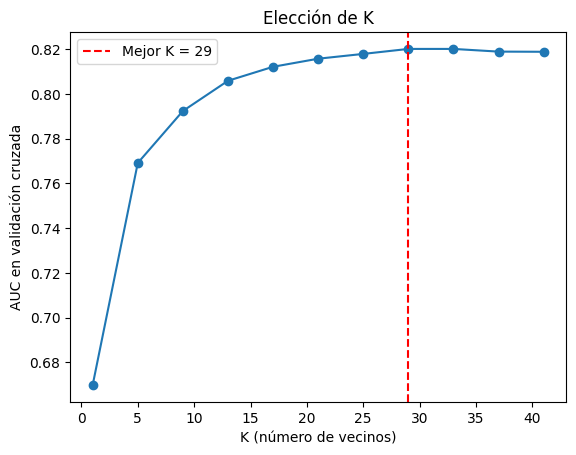

In [24]:
valores_k = range(1, 42, 4)
auc_por_k = []
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    auc = cross_val_score(knn, X_train_esc, y_train, cv=5, scoring="roc_auc").mean()
    auc_por_k.append(auc)

mejor_k = list(valores_k)[np.argmax(auc_por_k)]

plt.plot(list(valores_k), auc_por_k, marker="o")
plt.axvline(mejor_k, color="red", linestyle="--", label=f"Mejor K = {mejor_k}")
plt.xlabel("K (número de vecinos)")
plt.ylabel("AUC en validación cruzada")
plt.title("Elección de K")
plt.legend()
plt.show()

In [25]:
knn = KNeighborsClassifier(n_neighbors=mejor_k)
knn.fit(X_train_esc, y_train)
prob_knn = knn.predict_proba(X_test_esc)[:, 1]

evaluar(f"K-NN (K={mejor_k})", prob_knn)

,0
Accuracy,0.838
Recall,0.251
Precisión,0.836
Especificidad,0.987
F1,0.386
AUC,0.809
VP,102.000
FP,20.000
FN,305.000
VN,1573.000


3.4 Árbol de decisión

Hace preguntas de sí o no (¿edad > 42?, ¿es activo?) hasta separar a los que se van de los que se quedan. Usa el índice Gini para elegir la mejor pregunta.

Poda: un árbol muy profundo memoriza el entrenamiento y falla con clientes nuevos. Probamos profundidades de 1 a 12 y nos quedamos con la que da mejor resultado en validación.

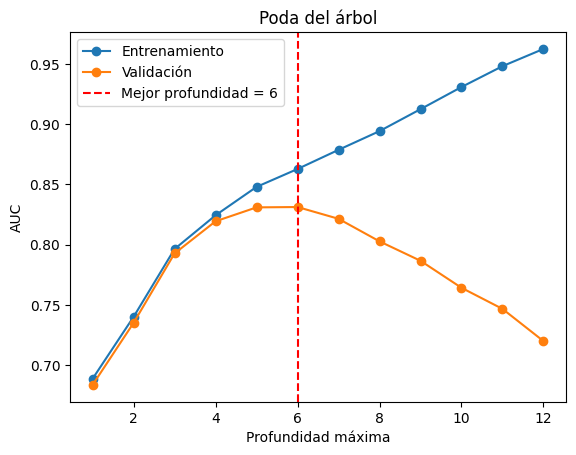

In [27]:
profundidades = range(1, 13)
auc_entrenamiento, auc_validacion = [], []

for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, criterion="gini", random_state=SEMILLA)
    auc_validacion.append(cross_val_score(arbol, X_train, y_train, cv=5, scoring="roc_auc").mean())
    arbol.fit(X_train, y_train)
    auc_entrenamiento.append(roc_auc_score(y_train, arbol.predict_proba(X_train)[:, 1]))

mejor_d = list(profundidades)[np.argmax(auc_validacion)]

plt.plot(list(profundidades), auc_entrenamiento, marker="o", label="Entrenamiento")
plt.plot(list(profundidades), auc_validacion, marker="o", label="Validación")
plt.axvline(mejor_d, color="red", linestyle="--", label=f"Mejor profundidad = {mejor_d}")
plt.xlabel("Profundidad máxima")
plt.ylabel("AUC")
plt.title("Poda del árbol")
plt.legend()
plt.show()

**Qué vemos:** la línea de entrenamiento sigue subiendo, pero la de validación se detiene y luego baja. Desde ahí el árbol ya está memorizando. Esa es la profundidad que elegimos.

*Nota: el árbol no necesita datos estandarizados, por eso usa X_train y no X_train_esc.

In [28]:
arbol = DecisionTreeClassifier(max_depth=mejor_d, criterion="gini", random_state=SEMILLA)
arbol.fit(X_train, y_train)
prob_arbol = arbol.predict_proba(X_test)[:, 1]

evaluar(f"Árbol (profundidad {mejor_d})", prob_arbol)

,0
Accuracy,0.860
Recall,0.442
Precisión,0.776
Especificidad,0.967
F1,0.563
AUC,0.840
VP,180.000
FP,52.000
FN,227.000
VN,1541.000


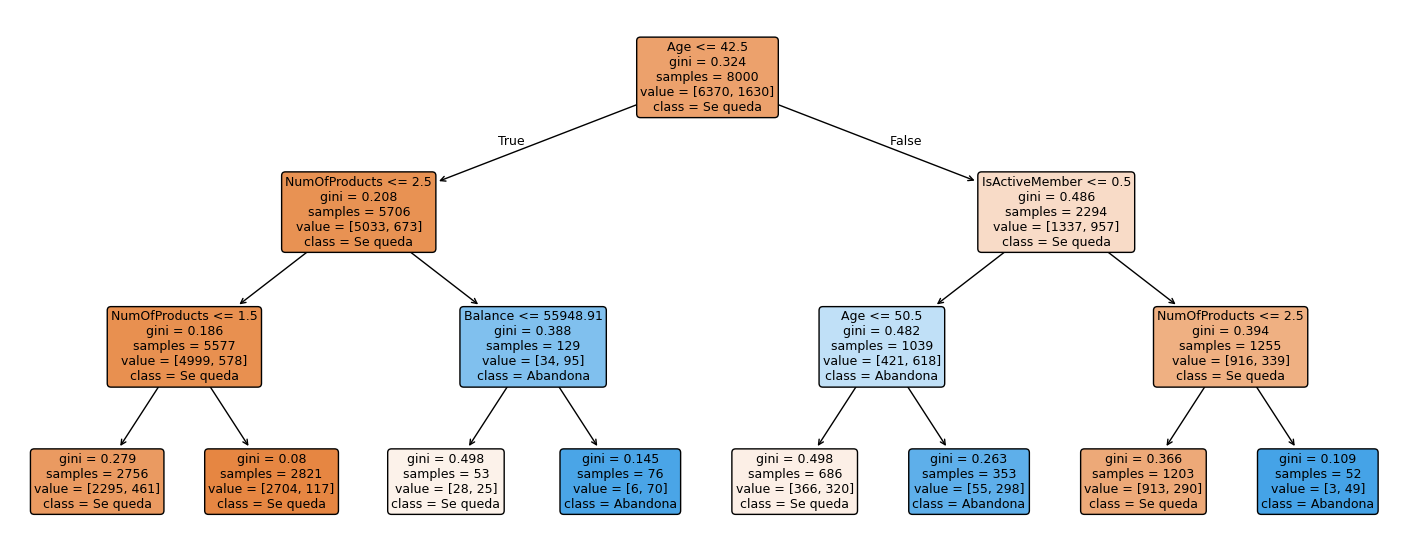

In [19]:
arbol_3 = DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=SEMILLA).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(arbol_3, feature_names=list(X.columns), class_names=["Se queda", "Abandona"],
          filled=True, rounded=True, fontsize=9)
plt.show()

**Qué vemos:** la primera pregunta es la **edad** (¿42.5 años o menos?). Después vienen ser **miembro activo** y el **número de productos**. Es la misma historia del mapa de calor, pero ahora como un diagrama de flujo.

### 3.5 Comparar los tres modelos

In [29]:
tabla = pd.DataFrame(resultados).T
tabla[["VP", "FP", "FN", "VN"]] = tabla[["VP", "FP", "FN", "VN"]].astype(int)
tabla.sort_values("AUC", ascending=False).round(3)

,Accuracy,Recall,Precisión,Especificidad,F1,AUC,VP,FP,FN,VN
Árbol (profundidad 6),0.860,0.442,0.776,0.967,0.563,0.840,180,52,227,1541
Árbol (prof=6),0.860,0.442,0.776,0.967,0.563,0.840,180,52,227,1541
K-NN (K=29),0.838,0.251,0.836,0.987,0.386,0.809,102,20,305,1573
Regresión logística,0.808,0.187,0.589,0.967,0.284,0.775,76,53,331,1540


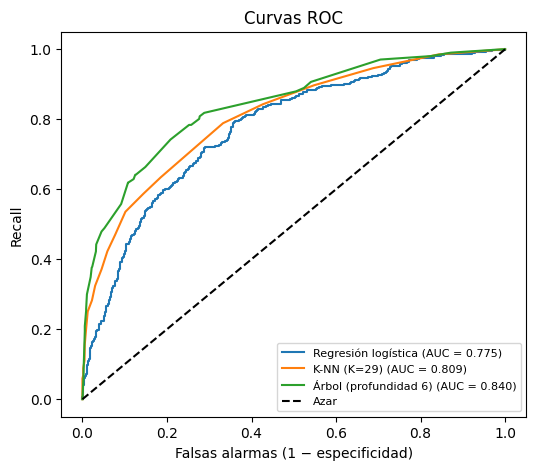

In [31]:
plt.figure(figsize=(6, 5))
for nombre, prob in [("Regresión logística", prob_log),
                     (f"K-NN (K={mejor_k})", prob_knn),
                     (f"Árbol (profundidad {mejor_d})", prob_arbol)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Falsas alarmas (1 − especificidad)")
plt.ylabel("Recall")
plt.title("Curvas ROC")
plt.legend(fontsize=8)
plt.show()

### 3.6 Elegir el umbral
Con el umbral de 0.5 el árbol deja escapar a más de la mitad de los que se van.
Como **perder un cliente cuesta más que hacer una llamada de más**, bajamos el umbral para detectar a más, aunque haya más falsas alarmas.

In [32]:
filas = []
for u in [0.5, 0.4, 0.3, 0.2]:
    pred = (prob_arbol >= u).astype(int)
    filas.append({"Umbral": u, "Recall": recall_score(y_test, pred),
                  "Precisión": precision_score(y_test, pred), "F1": f1_score(y_test, pred),
                  "Clientes a contactar": int(pred.sum())})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Recall,Precisión,F1,Clientes a contactar
Umbral,,,,
0.5,0.442,0.776,0.563,232
0.4,0.479,0.730,0.579,267
0.3,0.641,0.567,0.602,460
0.2,0.742,0.476,0.580,634


### Conclusión de la semana 8
- **Accuracy engaña.** Decir "nadie se va" ya da 79.7%. Por eso comparamos con **AUC** y **recall**.
- **El mejor modelo es el árbol** (profundidad 6): AUC de 0.840, F1 de 0.563 y el mejor recall con umbral 0.5 (44%). Además es el más fácil de explicar: sus primeras preguntas son la **edad** (más de 42 años), ser **miembro activo** y tener **3 o más productos**.
- **La regresión logística es la más débil** (AUC 0.775), por lo mismo que la recta: supone relaciones lineales.
- **El umbral 0.5 deja escapar a la mayoría de los que se van.** Como perder un cliente cuesta más que una llamada, priorizamos el recall: con umbral 0.3 el árbol detecta al **64%** de los que se van, contactando a 460 de 2,000 clientes (23%).

## 4 · Semana 9: Clustering
**Pregunta:** ¿qué grupos de clientes hay?

Aquí **no le decimos al modelo quién se fue**: es aprendizaje **no supervisado**. El modelo agrupa a los clientes parecidos y, al final, nosotros revisamos el abandono de cada grupo.


### 4.1 ¿Cuántos grupos? Método del codo y Silhouette
- **Inercia (J):** qué tan cerca está cada cliente del centro de su grupo. Buscamos el "codo", donde deja de bajar mucho.
- **Silhouette:** qué tan separados están los grupos (de −1 a 1; mientras más alto, mejor).

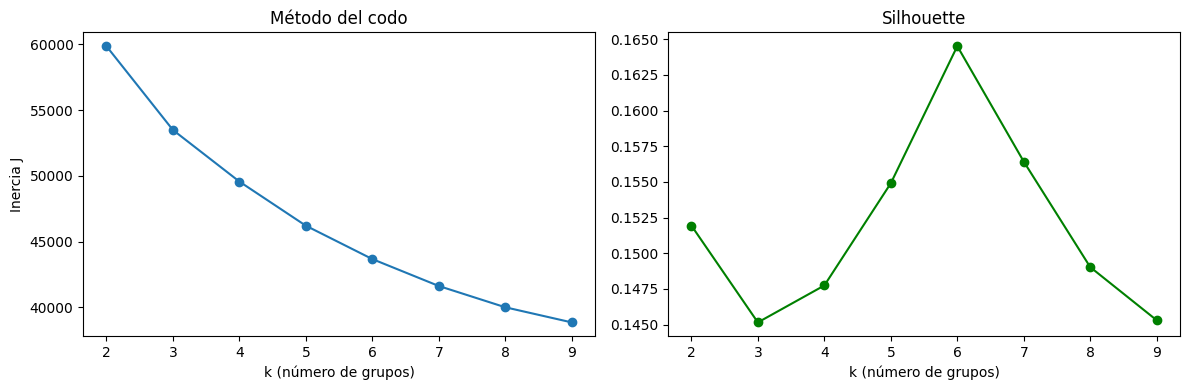

In [33]:
variables = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
             "IsActiveMember", "EstimatedSalary"]
X_std = StandardScaler().fit_transform(df[variables])

inercias, silhouettes = [], []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_std)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_std, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(range(2, 10), inercias, marker="o")
a1.set_title("Método del codo")
a1.set_xlabel("k (número de grupos)")
a1.set_ylabel("Inercia J")
a2.plot(range(2, 10), silhouettes, marker="o", color="green")
a2.set_title("Silhouette")
a2.set_xlabel("k (número de grupos)")
plt.tight_layout()
plt.show()

Qué vemos: el codo no es muy claro y el Silhouette es bajo en todos los casos (alrededor de 0.15). Los clientes no forman grupos muy separados. Elegimos k = 4 porque los grupos se pueden explicar bien en lenguaje de negocio.



### 4.2 K-Means con 4 grupos

In [34]:
K = 4
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=SEMILLA)
kmeans.fit(X_std)
df["Segmento"] = kmeans.labels_

# Perfil de cada grupo: promedio de cada variable y, al final, su abandono
perfil = df.groupby("Segmento").agg(
    clientes=("Exited", "size"),
    edad=("Age", "mean"),
    saldo=("Balance", "mean"),
    productos=("NumOfProducts", "mean"),
    activos=("IsActiveMember", "mean"),
    abandono=("Exited", "mean"),
).round(2)
perfil

,clientes,edad,saldo,productos,activos,abandono
Segmento,,,,,,
0,2876,35.30,107773.22,1.29,1.00,0.13
1,2761,35.92,9540.17,2.13,0.49,0.12
2,3247,37.47,105903.15,1.27,0.00,0.29
3,1116,59.88,75891.74,1.43,0.83,0.36


Al ver los promedios, le ponemos un nombre a cada grupo:

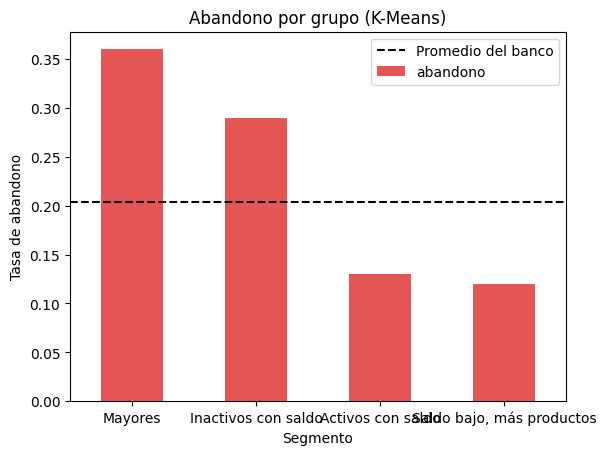

In [36]:
nombres = {0: "Activos con saldo", 1: "Saldo bajo, más productos",
           2: "Inactivos con saldo", 3: "Mayores"}
perfil.index = perfil.index.map(nombres)
perfil = perfil.sort_values("abandono", ascending=False)

perfil["abandono"].plot(kind="bar", color="#E45756")
plt.axhline(df["Exited"].mean(), color="black", linestyle="--", label="Promedio del banco")
plt.title("Abandono por grupo (K-Means)")
plt.ylabel("Tasa de abandono")
plt.xticks(rotation=0)
plt.legend()
plt.show()

**Qué vemos:** dos grupos están **por arriba del promedio** del banco: los **mayores** (36%) y los **inactivos con saldo** (29%). Esos son los que hay que cuidar.

4.3 Expectation-Maximization (EM): clustering suave
K-Means pone a cada cliente en un solo grupo. EM, con GaussianMixture, le da una probabilidad de pertenecer a cada grupo. Lo usamos para comparar: ¿EM encuentra mejores grupos que K-Means?

In [37]:
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=SEMILLA).fit(X_std)
probas = gmm.predict_proba(X_std)          # probas[i, j] = P(grupo j | cliente i)
df["Segmento_EM"] = gmm.predict(X_std)

print(f"Silhouette K-Means: {silhouette_score(X_std, df['Segmento']):.3f}")
print(f"Silhouette EM:      {silhouette_score(X_std, df['Segmento_EM']):.3f}")
print(f"Clientes con asignación dudosa en EM (probabilidad máxima < 0.6): {(probas.max(axis=1) < 0.6).mean():.1%}")
pd.crosstab(df["Segmento"], df["Segmento_EM"], rownames=["K-Means"], colnames=["EM"])

Silhouette K-Means: 0.148
Silhouette EM:      0.116
Clientes con asignación dudosa en EM (probabilidad máxima < 0.6): 0.0%


EM,0,1,2,3
K-Means,,,,
0,840,0,2036,0
1,162,1411,0,1188
2,0,3247,0,0
3,201,191,527,197


### Conclusión de la semana 9
- **El codo no es claro y el Silhouette es bajo** (0.15 con k = 4): los clientes no forman grupos naturales muy separados. Elegimos **k = 4** porque los grupos se explican bien en lenguaje de negocio.
- **Los cuatro segmentos:**

| Segmento | Perfil | Abandono |
|---|---|---|
| Mayores | Edad promedio de 60 años, la mayoría activos | 36% |
| Inactivos con saldo | Ninguno es activo, saldo promedio de 106 mil | 29% |
| Activos con saldo | Todos activos, saldo alto | 13% |
| Saldo bajo, más productos | Saldo promedio de 10 mil, 2.1 productos | 12% |

- **K-Means y EM no coinciden del todo**: EM tiene menor Silhouette (0.12) y reparte distinto a los clientes. Para decidir, K-Means es más simple de usar y de explicar.

## 5 · Conclusiones para el banco

**Respuesta al problema: ¿a quién retener primero?**

1. **Usar el árbol de decisión con umbral 0.3** para elegir a quién llamar: detecta a **casi 2 de cada 3** clientes que se van (64%), contactando solo a 460 de 2,000 clientes (23%).
2. **Dar prioridad a dos grupos:** los **mayores** (36% de abandono) y los **inactivos con saldo** (29%), que además tienen mucho dinero en el banco.
3. **Acciones sugeridas:**
    - inactivos con saldo → campaña de reactivación;
    - mayores → atención personalizada;
    - clientes con 3 o 4 productos → revisar por qué ese paquete hace que casi todos se vayan.

**Límites**
- Los modelos muestran relación, no causa: no sabemos por qué se va un cliente de Alemania o de 45 años.
- El umbral 0.3 se eligió viendo el conjunto de prueba; en un sistema real se elegiría con validación cruzada sobre el entrenamiento.
- No se sabe de qué banco ni de qué años son los datos, así que habría que probar los resultados con datos nuevos.